# Explore the warehouse

Look at any table in `data/warehouse.duckdb`. Everything is read-only.

**One rule:** DuckDB allows one writer at a time, and this notebook's read-only
connection blocks writers. Before `pixi run build`, run the last cell (or restart the
kernel). Tables and columns are described in `docs/data-dictionary.md`.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                 # the warehouse's staging views read raw files by paths relative to the repo root
sys.path.insert(0, str(ROOT))

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)

con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)


def q(sql):
    """Run SQL, get a DataFrame:  q("SELECT * FROM marts.mart_study__region_resilience LIMIT 5")"""
    return con.sql(sql).df()

## 1. Every table, with row counts

In [2]:
tables = q("""
    SELECT table_schema AS schema, table_name AS name, table_type AS type
    FROM information_schema.tables
    WHERE table_schema IN ('seeds', 'staging', 'intermediate', 'marts')
    ORDER BY schema, name
""")
# the national outage view reads ~250M rows of CSV: count it only if you mean to
tables["rows"] = [q(f"SELECT count(*) FROM {s}.{n}").iloc[0, 0] if n != "stg_eaglei__outages" else None
                  for s, n in zip(tables.schema, tables.name, strict=True)]
tables

,schema,name,type,rows
0,intermediate,int_eaglei__blocks_6h,BASE TABLE,16316.0
1,intermediate,int_study__outages_6h,BASE TABLE,1331862.0
2,intermediate,int_study__regions,BASE TABLE,216.0
3,intermediate,int_study__storm_events_6h,BASE TABLE,253533.0
4,intermediate,int_study__weather_6h,BASE TABLE,631584.0
5,marts,mart_study__region_6h,BASE TABLE,3524256.0
6,marts,mart_study__region_resilience,BASE TABLE,216.0
7,seeds,stl_metro_counties,BASE TABLE,8.0
8,staging,stg_acs__housing,VIEW,217.0
9,staging,stg_eaglei__customers,VIEW,3233.0


## 2. Columns of a table, and a preview

In [3]:
TABLE = "marts.mart_study__region_6h"
display(q(f"DESCRIBE {TABLE}"))
q(f"SELECT * FROM {TABLE} USING SAMPLE 5 ROWS")

,column_name,column_type,null,key,default,extra
0,region_fips,VARCHAR,YES,None,None,None
1,block_start,TIMESTAMP,YES,None,None,None
2,peak_out,HUGEINT,YES,None,None,None
3,peak_suspect,BOOLEAN,YES,None,None,None
4,peak_pct_out,DOUBLE,YES,None,None,None
5,mean_out,DOUBLE,YES,None,None,None
6,eaglei_snapshots,BIGINT,YES,None,None,None
7,has_weather,BOOLEAN,YES,None,None,None
8,gust_max_ms,DOUBLE,YES,None,None,None
9,wind10_max_ms,DOUBLE,YES,None,None,None


,region_fips,block_start,peak_out,peak_suspect,peak_pct_out,mean_out,eaglei_snapshots,has_weather,gust_max_ms,wind10_max_ms,wind850_max_ms,shear_0_6km_max_ms,cape_max_jkg,precip_sum_mm,precip_max_1h_mm,temp_min_c,temp_mean_c,freezing_level_min_m,icing_hours,hail_hours,region,state,customers,land_km2,housing_per_km2,share_homes_pre1960,median_year_built,canopy_mean_pct,canopy_dense_share,month,block_hour_utc,storm_reports,storm_tstm_wind,storm_max_wind_kt,storm_hail,storm_tornado,storm_high_wind,storm_winter
0,29093,2021-08-10 12:00:00,993.0,False,17.393589,435.041667,24,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,Iron,Missouri,5709.0,1425.174278,3.285212,0.281504,1974.0,68.38,0.8226,8,12,0,0,NaN,0,0,0,0
1,29065,2023-03-04 00:00:00,7.0,False,0.146413,0.875000,24,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,Dent,Missouri,4781.0,1949.641179,3.499105,0.222809,1978.0,52.70,0.6339,3,0,0,0,NaN,0,0,0,0
2,17201,2019-08-04 18:00:00,9.0,False,0.007451,1.250000,24,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,Winnebago,Illinois,120789.0,1328.792562,94.071869,0.354810,1971.0,12.97,0.1306,8,18,0,0,NaN,0,0,0,0
3,29095,2024-07-29 18:00:00,94.0,False,0.046451,40.750000,24,True,6.6,4.39,7.86,21.118213,3120.0,0.0,0.0,32.5,34.400000,4780.0,0,0,Jackson,Missouri,202364.0,1565.698759,214.784612,0.364878,1970.0,22.16,0.2080,7,18,0,0,NaN,0,0,0,0
4,17191,2024-09-30 06:00:00,1.0,False,0.009612,1.000000,24,True,5.1,2.28,10.18,20.657716,40.0,0.0,0.0,18.8,19.366667,4480.0,0,0,Wayne,Illinois,10404.0,1848.810381,4.154023,0.367188,1974.0,15.17,0.1778,9,6,0,0,NaN,0,0,0,0


## 3. One region through a storm

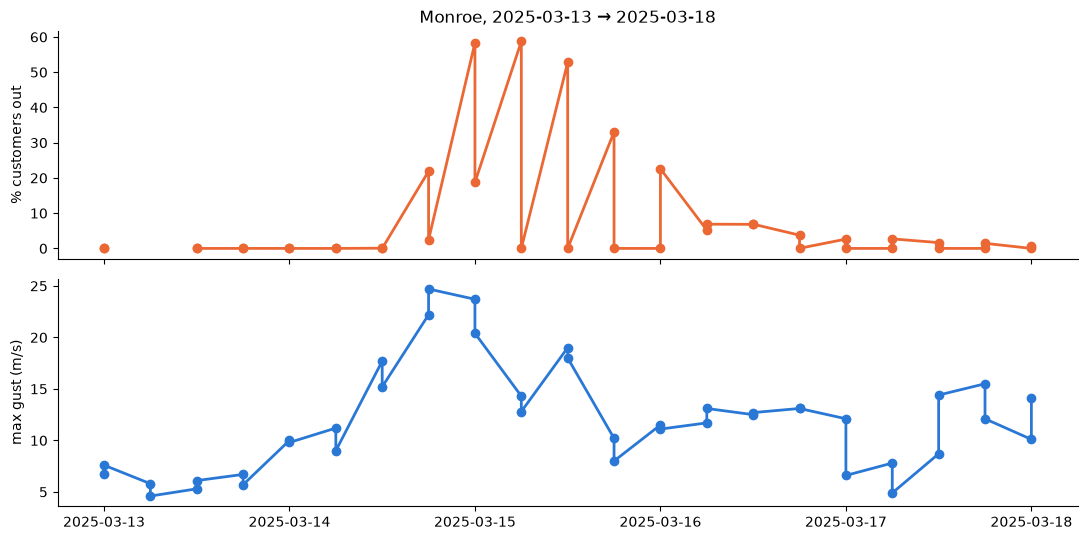

,block_start,peak_pct_out,peak_out,gust_max_ms,cape_max_jkg,precip_sum_mm,storm_reports
0,2025-03-13 00:00:00,0.000000,0.0,6.7,0.0,0.0,0
1,2025-03-13 00:00:00,0.000000,0.0,7.6,660.0,0.0,0
2,2025-03-13 06:00:00,NaN,NaN,5.8,0.0,0.0,0
3,2025-03-13 06:00:00,NaN,NaN,4.6,250.0,0.0,0
4,2025-03-13 12:00:00,0.006415,1.0,5.3,1680.0,0.0,0
5,2025-03-13 12:00:00,0.000000,0.0,6.1,250.0,0.0,0
6,2025-03-13 18:00:00,0.000000,0.0,6.7,840.0,0.0,0
7,2025-03-13 18:00:00,0.006415,1.0,5.7,2330.0,0.0,0
8,2025-03-14 00:00:00,0.000000,0.0,10.0,710.0,0.0,0
9,2025-03-14 00:00:00,0.000000,0.0,9.8,1410.0,0.0,0


In [4]:
REGION = "Monroe"                        # any region name, e.g. "St. Louis City + County", "Franklin"
START, END = "2025-03-13", "2025-03-18"  # the March 2025 tornado outbreak

ts = q(f"""
    SELECT block_start, peak_pct_out, peak_out, gust_max_ms, cape_max_jkg, precip_sum_mm, storm_reports
    FROM marts.mart_study__region_6h
    WHERE region = '{REGION}' AND block_start BETWEEN '{START}' AND '{END}'
    ORDER BY block_start
""")
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)   # two measures, two panels (no dual axis)
a.plot(ts.block_start, ts.peak_pct_out, "o-", color="#eb6834", lw=2)
a.set(ylabel="% customers out", title=f"{REGION}, {START} → {END}")
b.plot(ts.block_start, ts.gust_max_ms, "o-", color="#2a78d6", lw=2)
b.set(ylabel="max gust (m/s)")
for ax in (a, b):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
ts

## 4. The biggest outage blocks

In [5]:
q("""
    SELECT block_start,
           sum(peak_out)                                AS customers_out,
           count(*) FILTER (WHERE peak_pct_out >= 5)    AS regions_ge_5pct,
           sum(storm_reports)                           AS storm_reports
    FROM marts.mart_study__region_6h
    WHERE peak_out IS NOT NULL
    GROUP BY block_start
    ORDER BY customers_out DESC
    LIMIT 15
""")

,block_start,customers_out,regions_ge_5pct,storm_reports
0,2020-08-11 00:00:00,872982.0,52,48.0
1,2020-08-10 18:00:00,752198.0,48,334.0
2,2020-08-11 06:00:00,732424.0,36,1.0
3,2020-08-11 12:00:00,564731.0,29,2.0
4,2020-08-11 18:00:00,475168.0,26,2.0
5,2024-07-16 00:00:00,409211.0,33,339.0
6,2020-08-12 00:00:00,394022.0,24,0.0
7,2024-07-16 06:00:00,346586.0,33,22.0
8,2025-03-15 00:00:00,332037.0,70,439.0
9,2019-12-13 12:00:00,315327.0,0,0.0


## 5. Raw snapshots for a county

Straight from the EAGLE-I files (15-minute snapshots, before any merging). This scans
the national CSVs, so it takes a few seconds.

In [6]:
FIPS = "29510"          # St. Louis City; try 29189 (St. Louis County) too
q(f"""
    SELECT year(snapshot_time) AS year,
           count(*)                AS snapshots_with_outages,
           max(customers_out)      AS max_out,
           round(avg(customers_out)) AS avg_out
    FROM staging.stg_eaglei__outages
    WHERE fips_code = '{FIPS}'
    GROUP BY year
    ORDER BY year
""")

,year,snapshots_with_outages,max_out,avg_out
0,2014,1841,2428,31.0
1,2015,15759,3750,41.0
2,2016,22785,13923,134.0
3,2017,11477,3808,36.0
4,2018,20699,4168,62.0
5,2019,22010,5533,61.0
6,2020,25447,44212,250.0
7,2021,31287,69559,518.0
8,2022,33416,21020,237.0
9,2023,32628,83685,920.0


## 6. Do features separate outage blocks from quiet ones?

Distribution of one feature for blocks with and without a ≥ 5% outage (2024–2025, with
weather). Overlapping boxes = a weak feature on its own.

/var/folders/xh/l_wmyqk97tn2jq0mdftpyrgm0000gn/T/ipykernel_40160/2794762129.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([d.value[~d.outage].dropna(), d.value[d.outage].dropna()], vert=False, showfliers=False,


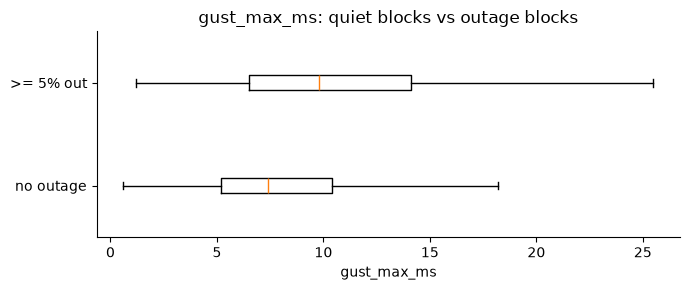

,count,mean,std,min,25%,50%,75%,max
outage,,,,,,,,
False,600492.0,8.14,4.00,0.6,5.2,7.4,10.4,31.1
True,5297.0,10.76,5.46,1.2,6.5,9.8,14.1,30.3


In [7]:
FEATURE = "gust_max_ms"   # try: shear_0_6km_max_ms, cape_max_jkg, precip_sum_mm, canopy_mean_pct
d = q(f"""
    SELECT {FEATURE} AS value, peak_pct_out >= 5 AS outage
    FROM marts.mart_study__region_6h
    WHERE has_weather AND peak_pct_out IS NOT NULL
""")
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([d.value[~d.outage].dropna(), d.value[d.outage].dropna()], vert=False, showfliers=False,
           tick_labels=["no outage", ">= 5% out"])
ax.set(xlabel=FEATURE, title=f"{FEATURE}: quiet blocks vs outage blocks")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
d.groupby("outage").value.describe().round(2)

## 7. Map a region metric

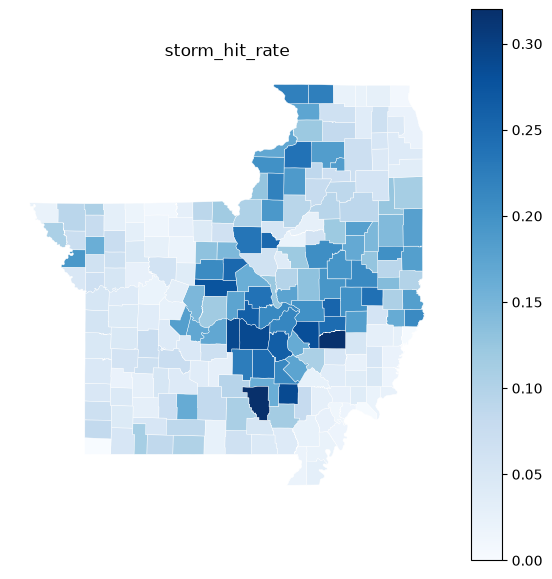

In [8]:
METRIC = "storm_hit_rate"   # any column of marts.mart_study__region_resilience
shapes = gpd.read_parquet(ROOT / "data" / "raw" / "geo" / "regions_study.parquet")
metric = q(f"SELECT region_fips, {METRIC} FROM marts.mart_study__region_resilience")
ax = shapes.merge(metric, on="region_fips").plot(column=METRIC, cmap="Blues", legend=True, figsize=(7, 8),
                                                 edgecolor="white", linewidth=0.3)
ax.set_axis_off()
ax.set_title(METRIC)
plt.show()

## Your own query

In [9]:
q("""
    SELECT state, count(*) AS regions, round(avg(canopy_mean_pct), 1) AS avg_canopy_pct
    FROM intermediate.int_study__regions
    GROUP BY state
""")

,state,regions,avg_canopy_pct
0,Illinois,102,15.7
1,Missouri,114,28.6


## Done? Release the database (needed before `pixi run build`)

In [10]:
con.close()